### 1. Preprocesarea datelor și scalarea (Min-Max, Normalizare, Log)

In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import plotly.graph_objects as go

from sklearn.preprocessing import MinMaxScaler, StandardScaler, Normalizer, OneHotEncoder
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, silhouette_samples

housing = pd.read_csv('../L2/AmesHousing_Clean.csv', sep='\t')
housing.columns = housing.columns.str.replace(' ', '').str.replace('_', '')

df_base = housing.copy()

drop_cols = [c for c in ['SalePrice', 'Order', 'PID'] if c in df_base.columns]

num_cols = [c for c in df_base.select_dtypes(include=np.number).columns if c not in drop_cols]
cat_cols = [c for c in df_base.select_dtypes(exclude=np.number).columns if c not in drop_cols]

# One-Hot Encoding pentru variabilele categorice
ohe = OneHotEncoder(sparse_output=False, handle_unknown='ignore', drop='first')
X_cat = pd.DataFrame(
    ohe.fit_transform(df_base[cat_cols]),
    columns=ohe.get_feature_names_out(cat_cols),
    index=df_base.index
)
X_num = df_base[num_cols].copy()
X_raw = pd.concat([X_num, X_cat], axis=1)

# 1. Min-Max Scaling
minmax_scaler = MinMaxScaler()
X_minmax = pd.DataFrame(minmax_scaler.fit_transform(X_raw), columns=X_raw.columns, index=X_raw.index)

# 2. StandardScaler
std_scaler = StandardScaler()
X_std = pd.DataFrame(std_scaler.fit_transform(X_raw), columns=X_raw.columns, index=X_raw.index)

# 3. Min-Max + Normalizer (L2 norm pe rânduri)
normalizer = Normalizer()
X_norm = pd.DataFrame(normalizer.fit_transform(X_minmax), columns=X_raw.columns, index=X_raw.index)

# 4. Log1p pe coloanele numerice asimetrice + Min-Max
X_log = X_raw.copy()
for col in num_cols:
    if (X_log[col] >= 0).all() and X_log[col].skew() > 1.0:
        X_log[col] = np.log1p(X_log[col])
X_log_scaled = pd.DataFrame(MinMaxScaler().fit_transform(X_log), columns=X_log.columns, index=X_log.index)

### 2. PCA și pragurile de varianță

Prag 98%: 137 componente principale (varianță cumulată = 0.9803)
Prag 95%: 100 componente principale (varianță cumulată = 0.9504)
Prag 90%: 73 componente principale (varianță cumulată = 0.9016)
Prag 80%: 44 componente principale (varianță cumulată = 0.8001)
PC1: 0.1543
PC2: 0.0633
PC3: 0.0388
PC4: 0.0340
PC5: 0.0298
PC6: 0.0282
PC7: 0.0274
PC8: 0.0241
PC9: 0.0228
PC10: 0.0202


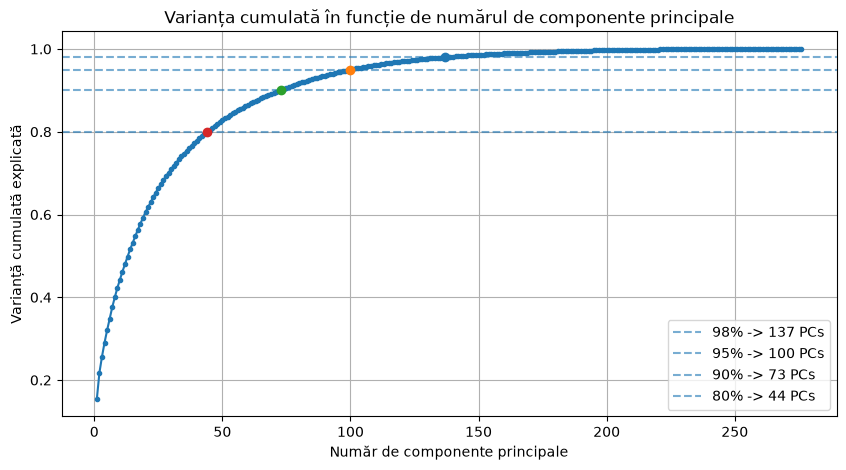

In [5]:
pca_full = PCA(random_state=42)
pca_full.fit(X_minmax)

cum_var = np.cumsum(pca_full.explained_variance_ratio_)
thresholds = [0.98, 0.95, 0.90, 0.80]
n_comp_by_thresh = {}

for t in thresholds:
    n_comp = int(np.argmax(cum_var >= t) + 1)
    n_comp_by_thresh[t] = n_comp
    print(f"Prag {int(t*100)}%: {n_comp} componente principale (varianță cumulată = {cum_var[n_comp-1]:.4f})")

for i in range(min(10, len(pca_full.explained_variance_ratio_))):
    print(f"PC{i+1}: {pca_full.explained_variance_ratio_[i]:.4f}")

plt.figure(figsize=(10, 5))
plt.plot(range(1, len(cum_var) + 1), cum_var, marker='o', markersize=3)
for t in thresholds:
    n_c = n_comp_by_thresh[t]
    plt.axhline(y=t, linestyle='--', alpha=0.6, label=f"{int(t*100)}% -> {n_c} PCs")
    plt.scatter([n_c], [cum_var[n_c - 1]], zorder=5)
plt.xlabel("Număr de componente principale")
plt.ylabel("Varianță cumulată explicată")
plt.title("Varianța cumulată în funcție de numărul de componente principale")
plt.legend()
plt.grid(True)
plt.show()

### 3. K-Means Clustering pe pragurile de varianță

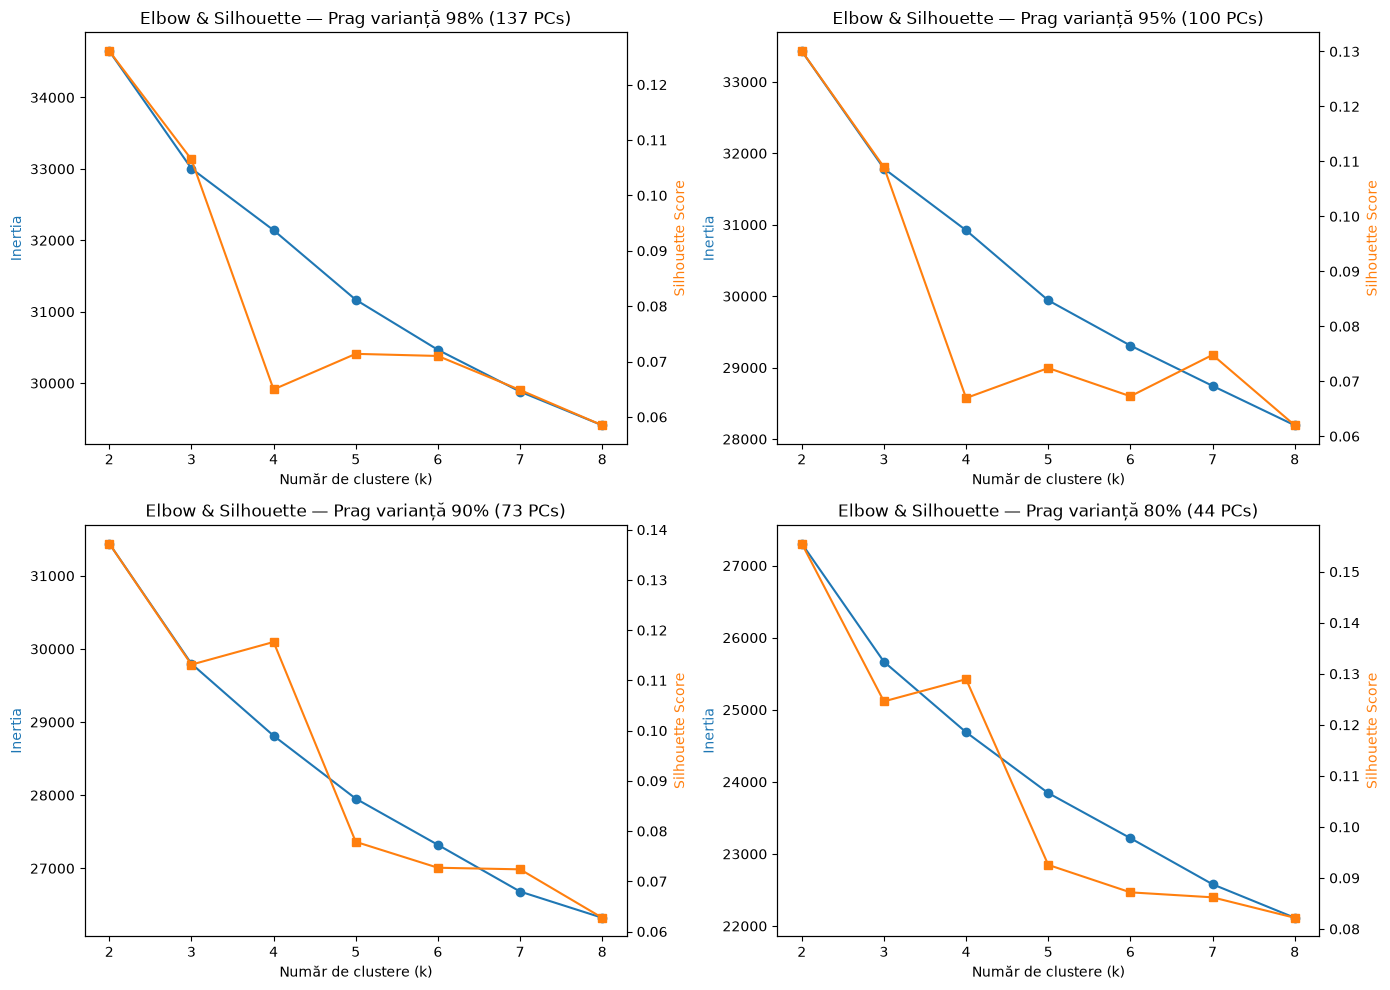

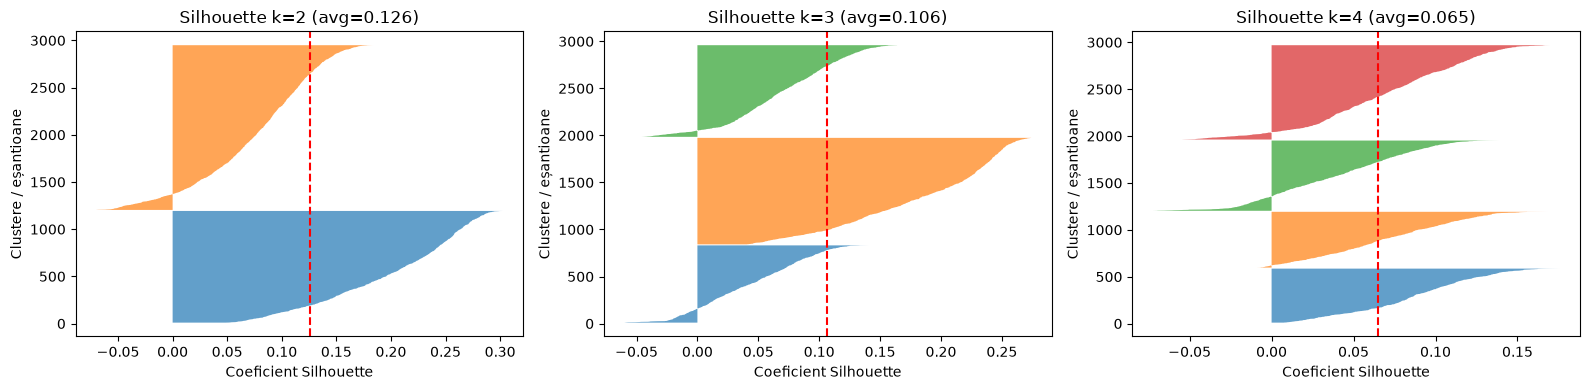

In [6]:
k_values = range(2, 9)
pca_models = {}
X_pca_sets = {}

for t in thresholds:
    pca_t = PCA(n_components=t, random_state=42)
    X_t = pca_t.fit_transform(X_minmax)
    pca_models[t] = pca_t
    X_pca_sets[t] = X_t

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes = axes.ravel()

for idx, t in enumerate(thresholds):
    X_t = X_pca_sets[t]
    inertias = []
    sil_scores = []
    for k in k_values:
        km = KMeans(n_clusters=k, random_state=42, n_init=10)
        labels_k = km.fit_predict(X_t)
        inertias.append(km.inertia_)
        sil_scores.append(silhouette_score(X_t, labels_k))
    ax1 = axes[idx]
    ax1.plot(list(k_values), inertias, marker='o', color='tab:blue', label='Inertia')
    ax1.set_xlabel("Număr de clustere (k)")
    ax1.set_ylabel("Inertia", color='tab:blue')
    ax1.set_title(f"Elbow & Silhouette — Prag varianță {int(t*100)}% ({X_t.shape[1]} PCs)")
    ax2 = ax1.twinx()
    ax2.plot(list(k_values), sil_scores, marker='s', color='tab:orange', label='Silhouette')
    ax2.set_ylabel("Silhouette Score", color='tab:orange')

plt.tight_layout()
plt.show()

best_k = 3
X_98 = X_pca_sets[0.98]
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for idx, k in enumerate([2, 3, 4]):
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    lbl = km.fit_predict(X_98)
    s_vals = silhouette_samples(X_98, lbl)
    s_avg = silhouette_score(X_98, lbl)
    y_lower = 10
    ax = axes[idx]
    for c in range(k):
        c_vals = np.sort(s_vals[lbl == c])
        y_upper = y_lower + len(c_vals)
        ax.fill_betweenx(np.arange(y_lower, y_upper), 0, c_vals, alpha=0.7)
        y_lower = y_upper + 10
    ax.axvline(x=s_avg, color="red", linestyle="--")
    ax.set_title(f"Silhouette k={k} (avg={s_avg:.3f})")
    ax.set_xlabel("Coeficient Silhouette")
    ax.set_ylabel("Clustere / eșantioane")

plt.tight_layout()
plt.show()

### 4. Vizualizare 2D (PC1 vs PC2) cu centroizi și comparația preprocesărilor

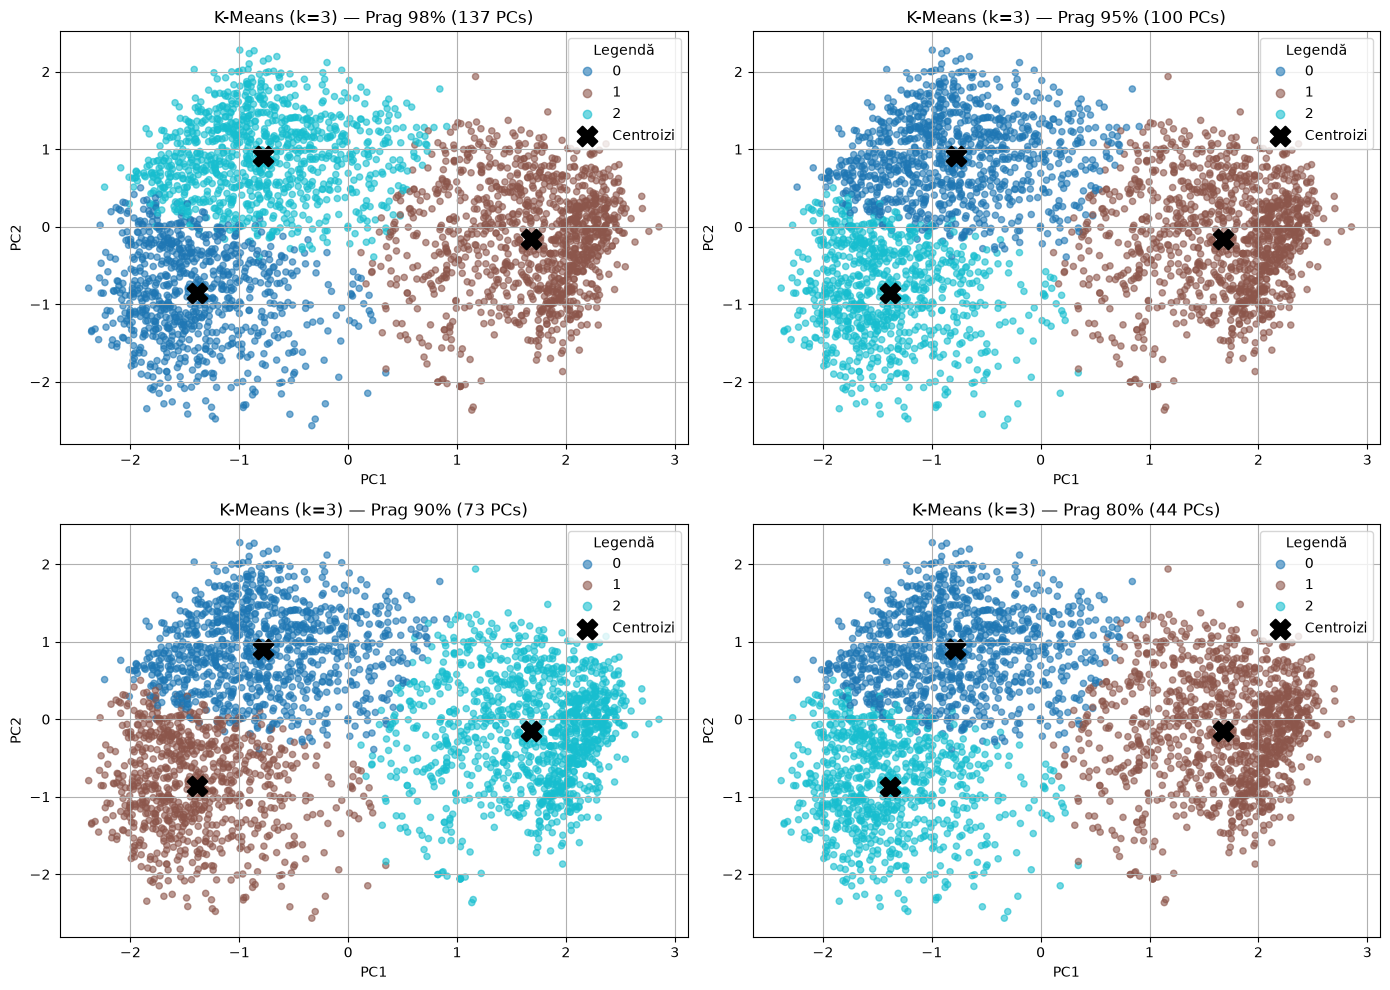

MinMax             | PCs: 137 | Silhouette: 0.1065 | Inertia: 33005.10
StandardScaler     | PCs: 207 | Silhouette: 0.0575 | Inertia: 732609.52
MinMax+Normalizer  | PCs: 137 | Silhouette: 0.1070 | Inertia: 794.17
Log1p+MinMax       | PCs: 138 | Silhouette: 0.1070 | Inertia: 34786.94


In [7]:
km_models = {}
clusters_by_thresh = {}

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes = axes.ravel()

for idx, t in enumerate(thresholds):
    X_t = X_pca_sets[t]
    km_t = KMeans(n_clusters=best_k, random_state=42, n_init=10)
    lbl_t = km_t.fit_predict(X_t)
    km_models[t] = km_t
    clusters_by_thresh[t] = lbl_t
    
    ax = axes[idx]
    scatter = ax.scatter(X_t[:, 0], X_t[:, 1], c=lbl_t, cmap='tab10', alpha=0.6, s=20)
    centroids_plot = ax.scatter(
        km_t.cluster_centers_[:, 0], km_t.cluster_centers_[:, 1],
        c='black', marker='X', s=200, linewidths=1.5, label='Centroizi'
    )
    ax.set_xlabel("PC1")
    ax.set_ylabel("PC2")
    ax.set_title(f"K-Means (k={best_k}) — Prag {int(t*100)}% ({X_t.shape[1]} PCs)")
    ax.grid(True)
    
    # Combinăm legenda clusterelor cu simbolul pentru centroizi
    handles, labels = scatter.legend_elements()
    handles.append(centroids_plot)
    labels.append("Centroizi")
    ax.legend(handles, labels, title="Legendă", loc="upper right")

plt.tight_layout()
plt.show()

# Comparația metodelor de preprocesare (la pragul de 98%)
variants = {
    "MinMax": X_minmax,
    "StandardScaler": X_std,
    "MinMax+Normalizer": X_norm,
    "Log1p+MinMax": X_log_scaled
}

for name, X_var in variants.items():
    pca_v = PCA(n_components=0.98, random_state=42)
    X_v_pca = pca_v.fit_transform(X_var)
    km_v = KMeans(n_clusters=best_k, random_state=42, n_init=10)
    lbl_v = km_v.fit_predict(X_v_pca)
    print(f"{name:18s} | PCs: {X_v_pca.shape[1]:3d} | Silhouette: {silhouette_score(X_v_pca, lbl_v):.4f} | Inertia: {km_v.inertia_:.2f}")

### 5. PCA loadings, profilul clusterelor și predicție pe case noi

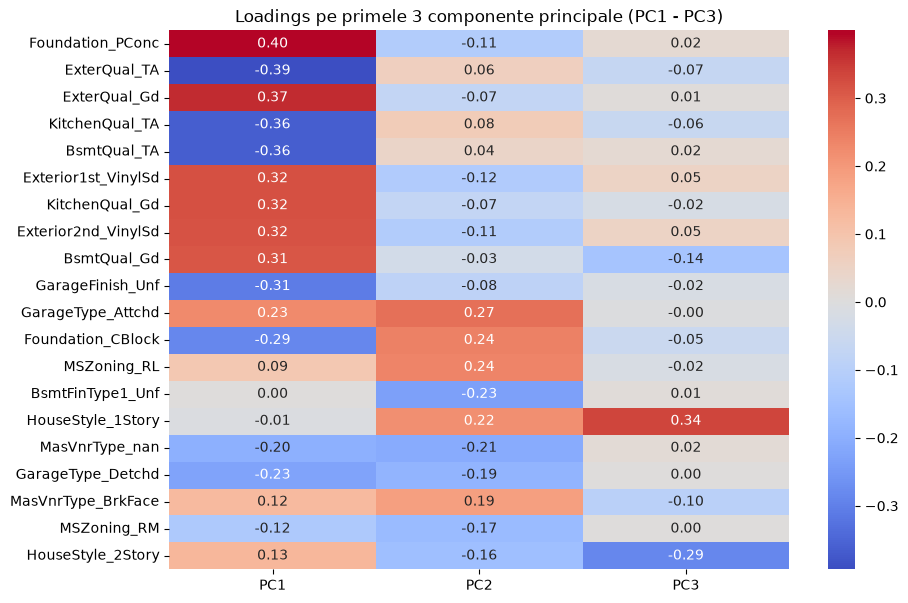

SalePrice                 OverallQual                 GrLivArea  \
                  mean    median count        mean median count         mean   
Cluster                                                                        
0        122742.874696  119900.0   822    5.062044    5.0   822  1316.772506   
1        243883.789056  221800.0  1133    7.320388    7.0  1133  1751.473963   
2        156428.184615  148325.0   975    5.541538    5.0   975  1361.318974   

                       TotalBsmtSF                  YearBuilt                \
         median count         mean  median count         mean  median count   
Cluster                                                                       
0        1242.0   822   770.360097   780.0   822  1937.012165  1935.0   822   
1        1662.0  1133  1268.058252  1247.0  1133  2000.855252  2003.0  1133   
2        1268.0   975  1037.151795  1029.0   975  1966.031795  1966.0   975   

         GarageArea               
               mean median count  
Cluster                           
0        329.860097  308.0   822  
1        601.914387  564.0  1133  
2        443.338462  451.0   975

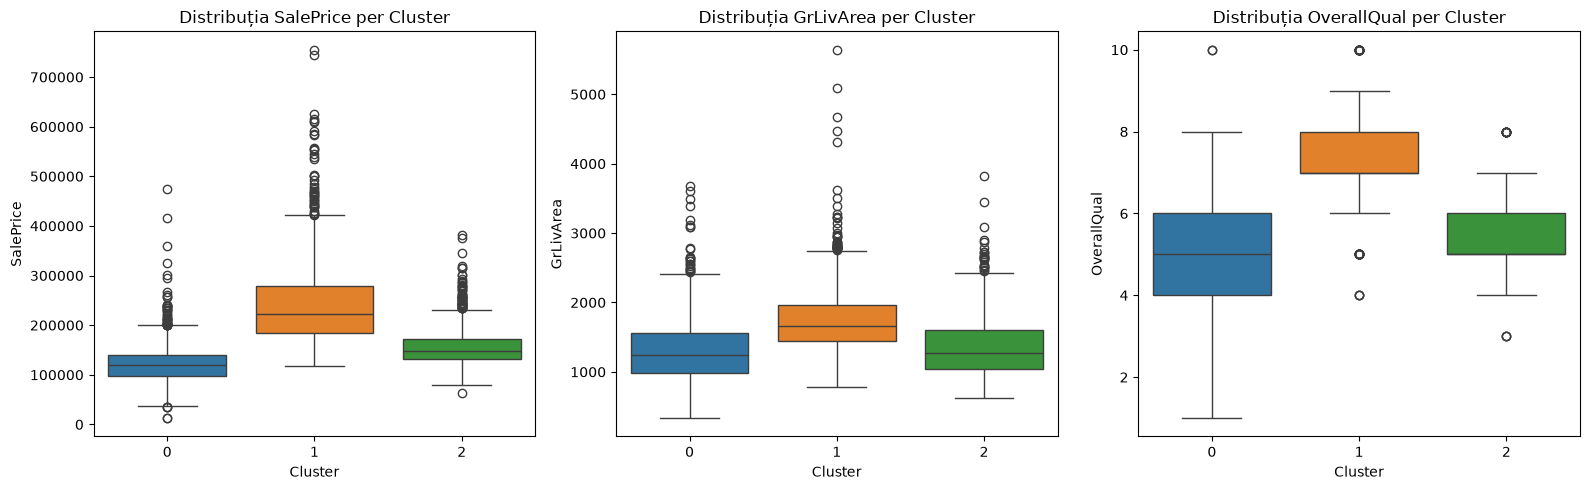

Casa nouă #1 -> Cluster 2
Casa nouă #2 -> Cluster 2
Casa nouă #3 -> Cluster 2


c:\Projects 2\ML\venv\Lib\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but PCA was fitted with feature names
  warnings.warn(


In [8]:
pca_best = pca_models[0.98]
km_98 = km_models[0.98]
clusters_98 = clusters_by_thresh[0.98]

loadings = pd.DataFrame(
    pca_best.components_.T * np.sqrt(pca_best.explained_variance_),
    index=X_minmax.columns,
    columns=[f"PC{i+1}" for i in range(pca_best.n_components_)]
)

top_pc1 = loadings["PC1"].abs().sort_values(ascending=False).head(10).index
top_pc2 = loadings["PC2"].abs().sort_values(ascending=False).head(10).index
top_feats = list(dict.fromkeys(list(top_pc1) + list(top_pc2)))

plt.figure(figsize=(10, 7))
sns.heatmap(loadings.loc[top_feats, ["PC1", "PC2", "PC3"]], annot=True, cmap="coolwarm", center=0, fmt=".2f")
plt.title("Loadings pe primele 3 componente principale (PC1 - PC3)")
plt.show()

# Profilul clusterelor (tabel + boxplot-uri)
df_profile = df_base.copy()
df_profile["Cluster"] = clusters_98
summary_cols = [c for c in ["SalePrice", "OverallQual", "GrLivArea", "TotalBsmtSF", "YearBuilt", "GarageArea"] if c in df_profile.columns]
display(df_profile.groupby("Cluster")[summary_cols].agg(["mean", "median", "count"]))

fig, axes = plt.subplots(1, 3, figsize=(16, 5))
for ax, col in zip(axes, ["SalePrice", "GrLivArea", "OverallQual"]):
    if col in df_profile.columns:
        sns.boxplot(data=df_profile, x="Cluster", y=col, ax=ax, palette="tab10", hue="Cluster", legend=False)
        ax.set_title(f"Distribuția {col} per Cluster")
plt.tight_layout()
plt.show()

# Predicție pe 3 case noi (folosind mediana pentru numerice și modul pentru categorice)
new_houses_dict = {
    col: [df_base[col].median() if col in num_cols else df_base[col].mode()[0] for _ in range(3)]
    for col in (num_cols + cat_cols)
}
new_houses = pd.DataFrame(new_houses_dict)

# Setăm profiluri distincte: casă mică/veche, medie, mare/nouă
if "OverallQual" in new_houses.columns: new_houses["OverallQual"] = [4, 7, 9]
if "GrLivArea" in new_houses.columns:   new_houses["GrLivArea"]   = [900, 1650, 2800]
if "YearBuilt" in new_houses.columns:   new_houses["YearBuilt"]   = [1955, 2002, 2018]
if "GarageArea" in new_houses.columns:  new_houses["GarageArea"]  = [0, 480, 820]

new_cat = pd.DataFrame(
    ohe.transform(new_houses[cat_cols]),
    columns=ohe.get_feature_names_out(cat_cols)
)
new_combined = pd.concat([new_houses[num_cols].reset_index(drop=True), new_cat], axis=1)
new_scaled = minmax_scaler.transform(new_combined)
new_pca = pca_best.transform(new_scaled)
pred_clusters = km_98.predict(new_pca)

for i, c in enumerate(pred_clusters):
    print(f"Casa nouă #{i+1} -> Cluster {c}")